# 文章の品質推定と解釈可能なシステム設計（接続表現ハイライト・線形モデルの根拠提示・特徴量ベース vs 微調整）

書籍 第2章「分類・回帰問題の解き方」（2-3 文章の品質推定：2-3-2 アプローチ、図 2.4・図 2.5、p.67〜71、関連論文 2章 7）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、自動採点・文章品質推定における「説明可能性・信頼度提示」と「特徴量ベース vs ファインチューニングベース」の設計トレードオフを体験します。

1. **ルールベース＋統計ベースによる作文の特徴抽出と接続表現ハイライト（2-3-2・図 2.4）**: GoodWriting Rater のように接続表現をカテゴリ別に可視化し、文字種比率・語彙多様性・文章長などの定量特徴量と品質スコアの関係を確認します。
2. **機械学習ベースの解釈可能性（2-3-2・関連論文 2章 7）**: 分類モデル (`LogisticRegression`) の予測確率「信頼度」で確信ある判定と境界上の迷いを区別し、線形回帰モデル（`SVR(kernel="linear")`・`Ridge`）の重みと個別作文への寄与内訳から根拠を提示します。
3. **特徴量ベース vs ファインチューニングベース（2-3-2・図 2.5）**: 一般コーパスで事前学習した軽量表現ネットワークを用い、少データ ($N=12, 20$) での「表現層凍結 + 線形 SVR」「控えめなファインチューニング」「過剰なファインチューニング」を比較して、過学習と**破壊的忘却**（catastrophic forgetting, p.70 脚注 60）を実証します。

---

## 1. ルールベース＋統計ベースによる作文の特徴抽出と接続表現ハイライト（2-3-2・図 2.4）

書籍 2-3-2（図 2.4「GoodWriting Rater」）では、作文に対して **総文字数・平均文長・漢字割合・語彙多様性・接続表現の使用状況** などの統計量を取り出し、さらにテキスト中の接続表現を強調表示（ハイライト）して書き手・指導者へフィードバックするルールベース／統計ベースの枠組みが紹介されています。

ここでは 1〜5 の 5 段階品質スコアが付いた日本語の意見文サンプル 30 件（各スコア 6 件ずつ：長さの割に単調なスコア 2 や簡潔だが構造が整ったスコア 4 など現実的な境界例も含む）を用意し、接続表現ハイライトと特徴量統計を実装します。

=== 接続表現ハイライトの例 (GoodWriting Rater 風) ===
[スコア 1] スマホはべんりです。みんなつかっています。たのしいとおもいます。

[スコア 3] 紙の辞書と電子辞書にはそれぞれ長所がある。電子辞書は検索が速く、発音もすぐ確認できる。[逆接:しかし]、紙の辞書は周辺の語も自然に目に入る点が優れている。[因果:したがって]、目的に応じて使い分けるのが良い。

[スコア 5] 再生可能エネルギーの導入拡大は脱炭素社会の実現に不可欠だが、電力供給の安定性との両立が課題となる。太陽光や風力は天候に[結論:よって]発電量が大きく変動する[因果:ためである]。[累加:さらに]、発電適地と電力消費地が離れている場合には送電網の増強も必要になる。[逆接:一方で]、大型蓄電池の技術革新や需要側での電力制御を組み合わせることで変動を吸収する仕組みも実用化されつつある。[逆接:ところが]、初期投資の負担が地域電力会社の経営を圧迫する側面は否定できない。[結論:以上のことから]、蓄電インフラへの計画的投資と広域融通制度の整備を並行して進めるべきである。

=== スコア別の特徴量平均値（30件） ===


,総文字数,文数,平均文長,漢字率,ひらがな率,カタカナ率,文字2gram多様性(TTR),接続表現数,接続表現カテゴリ数
スコア,,,,,,,,,
1,32.667,3.000,10.889,0.046,0.826,0.026,0.890,0.000,0.000
2,59.667,2.833,21.361,0.313,0.592,0.046,0.934,0.000,0.000
3,93.500,4.000,23.375,0.400,0.497,0.039,0.951,1.833,1.833
4,158.667,4.833,32.608,0.453,0.438,0.050,0.942,4.500,3.500
5,263.000,6.000,43.833,0.499,0.420,0.036,0.918,5.667,4.000


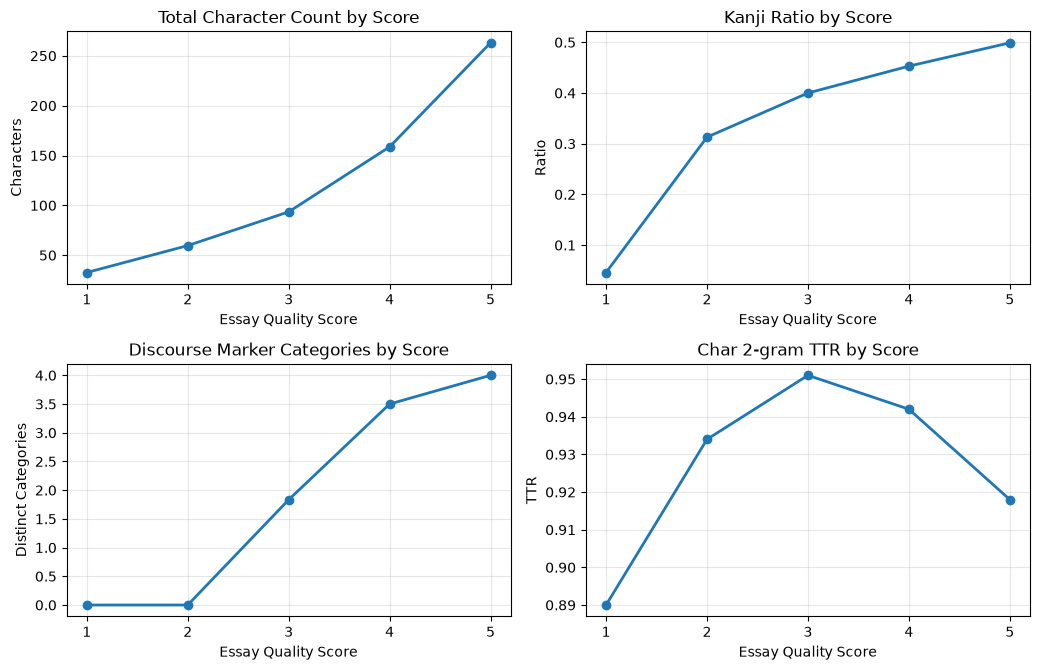

In [1]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import cohen_kappa_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

essays = [
    # スコア 1 (6件)
    (1, "スマホはべんりです。みんなつかっています。たのしいとおもいます。"),
    (1, "読書はいいです。ほんをよむといろいろわかります。もっとよみたいです。"),
    (1, "運動はたいせつです。まいにちあるくといいです。げんきになります。"),
    (1, "英語はむずかしいです。でもがんばります。すこしずつおぼえます。"),
    (1, "ゴミを減らすことは大事です。みんなできをつけましょう。おわりです。"),
    (1, "AIはすごいです。これからふえるとおもいます。べんきょうしたいです。"),
    # スコア 2 (6件; 5件目は文字数は多いが接続表現がなく単調な構成)
    (2, "リモート授業は通学時間が減って便利です。家で受けられるので朝が楽です。友達と話しにくいのが少し困ります。"),
    (2, "キャッシュレス決済は支払いが速くて便利です。小銭を出さずに済みます。ただ使いすぎに注意が必要だと思います。"),
    (2, "食品ロスを減らすには買いすぎないことが大切です。冷蔵庫の中を確認してから買い物に行くようにしたいです。"),
    (2, "図書館は静かで勉強しやすい場所です。無料で本を借りられるのも助かります。もっと席が多いと嬉しいです。"),
    (2, "睡眠不足になると授業に集中できなくなります。だから毎日同じ時間に寝て同じ時間に起きることがとても大事だとおもいます。夜に動画をずっと見ないようにきをつけたいです。生活リズムを整えると健康にもいいです。"),
    (2, "地域のお祭りは世代をこえて交流できる良い機会です。準備は大変そうですがこれからも続いてほしいと思います。"),
    # スコア 3 (6件)
    (3, "通学に自転車を使う学生が増えている。電車より費用を抑えられる点が魅力だ。一方で、雨の日の転倒や駐輪場の混雑という課題もある。そのため、交通ルールを守り安全に利用する意識が求められる。"),
    (3, "紙の辞書と電子辞書にはそれぞれ長所がある。電子辞書は検索が速く、発音もすぐ確認できる。しかし、紙の辞書は周辺の語も自然に目に入る点が優れている。したがって、目的に応じて使い分けるのが良い。"),
    (3, "地方移住への関心が高まっている。自然豊かな環境で子育てできることが主な理由である。ただし、医療機関や公共交通の便が都市部より限られる場合もある。この点を事前に確認することが大切だ。"),
    (3, "アルバイトは社会経験を積む良い機会になる。また、時間管理や敬語の使い方を学ぶこともできる。ところが、シフトを入れすぎると学業に支障が出る恐れがある。よって、学業との両立を第一に考えるべきだ。"),
    (3, "ペットと暮らすことは生活に癒やしをもたらす。毎日の散歩が運動不足の解消につながる例も多い。一方で、医療費や飼育の手間は決して小さくはない。そのため、最後まで責任を持てるか検討する必要がある。"),
    (3, "オンライン会議は移動コストを削減できる点で非常に有効だ。遠方の担当者とも短時間で打ち合わせが可能になった。しかし、微妙な表情や空気感を読み取りにくい面もある。対面の会議と併用するのが望ましい。"),
    # スコア 4 (6件; 4件目は比較的簡潔だが4種類の接続表現・構成が整う)
    (4, "近年、多くの学校でタブレット端末を活用した授業が広がっている。なぜなら、動画や図解を即座に共有でき、生徒の理解を助けるからだ。また、個人の習熟度に合わせて学習履歴を記録できる点も大きい。一方で、長時間の画面注視による視力低下や集中力の散漫も懸念される。したがって、紙のノートとデジタル教材の長所を組み合わせた運用が不可欠である。"),
    (4, "都市部の緑地を増やす取り組みは住民の生活の質を高める上で重要だ。公園や街路樹が増えることで夏場のヒートアイランド現象が緩和されるためである。さらに、災害時の一時避難場所としての機能も果たす。とはいえ、維持管理にかかる財政負担や落ち葉処理などの課題も残る。このように、市民ボランティアと自治体が協力して持続可能な管理体制を築くことが求められる。"),
    (4, "企業のテレワーク定着は働き方改革を大きく前進させた。通勤時間の削減により育児や介護との両立がしやすくなったからである。加えて、地方在住の優秀な人材を採用できる機会も広がった。しかし、新入社員が業務の相談をしづらく孤立感を受けやすいという問題もある。以上のことから、定期的な対話の場を設けて組織内の一体感を維持する工夫が必要だ。"),
    (4, "公共図書館の役割は単なる貸出施設から地域の知識拠点へと変化している。例えば、デジタル活用教室や地域の歴史資料の電子公開が進む。一方で、専門司書の不足という課題もある。よって、広域連携によって資源を共有すべきだ。"),
    (4, "観光地のオーバーツーリズム対策は持続可能な地域経済を保つために急務となっている。来訪者の集中が交通渋滞や住民の生活環境悪化を引き起こしているためだ。例えば、事前予約制の導入や早朝観光の推奨によって混雑を分散させる試みが始まった。一方で、過度な規制は地域収入の減少を招くおそれがある。このことから、住民の暮らしと観光収益の均衡を図る計画が大切である。"),
    (4, "生成AIの普及に伴い、教育現場では情報活用能力の育成が一層重要になっている。なぜなら、AIが生成する文章には事実と異なる内容が混ざる可能性があるからだ。さらに、出力の妥当性を自ら検証する批判的思考力が欠かせない。しかし、利用を一律に禁止するだけでは実践的な判断力は育たない。したがって、適切な利用指針を示した上で検証プロセスを指導することが望ましい。"),
    # スコア 5 (6件)
    (5, "再生可能エネルギーの導入拡大は脱炭素社会の実現に不可欠だが、電力供給の安定性との両立が課題となる。太陽光や風力は天候によって発電量が大きく変動するためである。さらに、発電適地と電力消費地が離れている場合には送電網の増強も必要になる。一方で、大型蓄電池の技術革新や需要側での電力制御を組み合わせることで変動を吸収する仕組みも実用化されつつある。ところが、初期投資の負担が地域電力会社の経営を圧迫する側面は否定できない。以上のことから、蓄電インフラへの計画的投資と広域融通制度の整備を並行して進めるべきである。"),
    (5, "医療分野における電子カルテの標準化は診断の質と業務効率を飛躍的に高める可能性を秘めている。なぜなら、転院時にも過去の検査値や処方履歴を正確に引き継ぐことができ、重複検査や投薬ミスを防げるからだ。加えて、匿名化された診療データの蓄積は新薬開発や疫学研究の基盤となる。しかし、医療機関ごとに異なる既存システムの改修費用や情報漏洩への懸念が導入の障壁となってきた。とはいえ、国際標準規格への準拠と堅牢な認証基盤の整備を進めれば安全性は確保できる。このように、公的支援と技術標準化の両輪によって医療情報の連携体制を確立することが急務である。"),
    (5, "自動運転技術の社会実装は高齢化が進む地域の移動手段を確保する上で極めて有効な解決策である。運転免許返納後の買い物や通院の困難を解消し、孤立を防ぐ効果が期待できるためだ。また、人為的ミスの削減による交通事故の減少にも大きく寄与する。一方で、悪天候時のセンサー認識精度の低下や事故発生時の法的責任の所在など未解決の論点も残る。例えば、限定地域での遠隔監視付き運行から段階的に検証を重ねる手法が現実的である。総じて、技術開発と法制度の整備を密接に連動させながら社会的信頼を醸成していくことが不可欠だ。"),
    (5, "防災教育を学校と地域の連携によって継続的に実施することは自然災害による被害を最小限に抑える鍵となる。災害発生時にはマニュアルの暗記だけでなく、状況に応じて自ら避難経路を判断する力が生死を分けるからである。さらに、児童生徒が家庭で防災知識を共有することで地域全体の備えも底上げされる。しかし、授業時数の制約から十分な訓練時間を確保できない学校が少なくない。とはいえ、地域の防災訓練と学校の総合学習を統合すれば負担を抑えつつ実践的な演習が可能になる。以上のことから、日常の学習活動に地域防災を組み込む持続可能な連携枠組みを構築すべきである。"),
    (5, "多言語共生社会の進展に伴い、行政文書の「やさしい日本語」への書き換えが重要な施策として注目されている。難解な専門用語や長い複文を平易な表現に改めることで、外国人住民だけでなく高齢者や子どもにも正確な情報が届くためである。加えて、災害時の緊急周知においては迅速な理解が安全確保に直結する。一方で、法令上の厳密な定義を簡略化する際に意味の取り違えが生じないよう慎重な検証が求められる。例えば、専門家の監修を受けた用語対照表とチェックリストの活用が有効だ。このように、正確性と伝達しやすさを両立させた情報発信の標準化を進めることが望ましい。"),
    (5, "大学におけるデータサイエンス教育は文系・理系を問わずあらゆる専攻の学生にとって必須の基盤となりつつある。現代の社会課題の多くは定量的な根拠に基づいて施策の効果を検証し、意思決定を行う必要があるためだ。さらに、統計的な推論と専門分野の知見を結びつけることで新たな研究領域が開拓される。ところが、数理的な基礎知識の差が大きい学生に対して画一的な講義を行うと学習意欲の低下を招きやすい。したがって、実社会の身近な課題データを題材にした演習を通じて実践的に理解を深める教育設計が不可欠である。総じて、基礎理論と応用演習を往還する体系的なカリキュラムが求められる。"),
]

DM_DICT = {
    "因果": ["そのため", "したがって", "なぜなら", "このため", "ゆえに", "ためである", "ためだ", "からだ", "からである"],
    "逆接": ["しかし", "一方で", "ところが", "ただし", "とはいえ"],
    "累加": ["さらに", "また", "例えば", "加えて", "その上"],
    "結論": ["このように", "以上のことから", "よって", "総じて", "つまり", "このことから"],
}

def highlight_discourse_markers(text):
    markers = sorted(
        [(w, cat) for cat, words in DM_DICT.items() for w in words],
        key=lambda x: len(x[0]),
        reverse=True,
    )
    pattern = re.compile("|".join(re.escape(w) for w, _ in markers))
    cat_map = dict(markers)
    return pattern.sub(lambda m: f"[{cat_map[m.group(0)]}:{m.group(0)}]", text)

def extract_essay_features(text):
    clean = re.sub(r"\s+", "", text)
    n_chars = len(clean)
    sents = [s for s in re.split(r"[。！？]+", clean) if s]
    n_sents = max(len(sents), 1)
    avg_sent_len = n_chars / n_sents
    kanji = sum(1 for c in clean if "\u4e00" <= c <= "\u9fff")
    hira = sum(1 for c in clean if "\u3040" <= c <= "\u309f")
    kata = sum(1 for c in clean if "\u30a0" <= c <= "\u30ff")
    bigrams = [clean[i:i + 2] for i in range(max(len(clean) - 1, 0))]
    ttr_2gram = len(set(bigrams)) / max(len(bigrams), 1)
    dm_cnt, dm_cats = 0, 0
    for words in DM_DICT.values():
        hits = sum(clean.count(w) for w in words)
        dm_cnt += hits
        if hits > 0:
            dm_cats += 1
    return {
        "総文字数": n_chars,
        "文数": n_sents,
        "平均文長": avg_sent_len,
        "漢字率": kanji / max(n_chars, 1),
        "ひらがな率": hira / max(n_chars, 1),
        "カタカナ率": kata / max(n_chars, 1),
        "文字2gram多様性(TTR)": ttr_2gram,
        "接続表現数": dm_cnt,
        "接続表現カテゴリ数": dm_cats,
    }

print("=== 接続表現ハイライトの例 (GoodWriting Rater 風) ===")
for idx in [0, 13, 24]:
    sc, txt = essays[idx]
    print(f"[スコア {sc}] {highlight_discourse_markers(txt)}\n")

df_essays = pd.DataFrame([{"スコア": sc, "本文": txt, **extract_essay_features(txt)} for sc, txt in essays])
feat_cols = [c for c in df_essays.columns if c not in ("スコア", "本文")]

print("=== スコア別の特徴量平均値（30件） ===")
mean_by_score = df_essays.groupby("スコア")[feat_cols].mean().round(3)
display(mean_by_score)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.8))
plot_specs = [
    ("総文字数", "Total Character Count by Score", "Characters"),
    ("漢字率", "Kanji Ratio by Score", "Ratio"),
    ("接続表現カテゴリ数", "Discourse Marker Categories by Score", "Distinct Categories"),
    ("文字2gram多様性(TTR)", "Char 2-gram TTR by Score", "TTR"),
]
scores_x = mean_by_score.index.to_numpy()
for ax, (col, title, ylab) in zip(axes.ravel(), plot_specs):
    ax.plot(scores_x, mean_by_score[col].to_numpy(), marker="o", linewidth=2)
    ax.set_xticks(scores_x)
    ax.set_xlabel("Essay Quality Score")
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

## 2. 機械学習ベースの解釈可能性：信頼度の提示と線形モデルの素性重み分析（2-3-2・関連論文 2章 7）

書籍 2-3-2 (p.68) および関連論文 2章 7（Hirao et al., LREC 2020「*Automated Essay Scoring with Interpretable Features*」）では、教育現場などで作文の自動評価を使う際に「点数だけを出して根拠がわからないブラックボックス」ではなく、**予測の確からしさ（信頼度）や寄与した素性を提示できる解釈可能なモデル**が重要であることが論じられています。

ここでは 30 件の作文を層化分割（訓練 20 件 / テスト 10 件）し、次を確かめます。
1. **分類 (`LogisticRegression`) による予測確率「信頼度」の提示**: 確信を持ってスコアを判定できている作文と、隣接スコア間で迷っている境界上の作文の識別。
2. **線形回帰 (`SVR(kernel="linear")` / `Ridge`) による素性重み分析と個別寄与内訳**: 標準化した解釈可能素性の学習済み重み $w_j$ と、個別のテスト作文に対する寄与 $w_j z_j$ の算出。

LogisticRegression テスト QWK: 0.955


,テストID,正解,予測,信頼度(最大確率),各スコア確率 [1..5],冒頭
0,0,2,2,0.772,"[0.05, 0.77, 0.17, 0.01, 0.0]",地域のお祭りは世代をこえて交流できる良い機会です…
1,1,4,4,0.417,"[0.0, 0.01, 0.36, 0.42, 0.21]",企業のテレワーク定着は働き方改革を大きく前進させ…
2,2,3,2,0.511,"[0.01, 0.51, 0.35, 0.13, 0.01]",オンライン会議は移動コストを削減できる点で非常に…
3,3,1,1,0.445,"[0.45, 0.42, 0.13, 0.01, 0.0]",ゴミを減らすことは大事です。みんなできをつけまし…
4,4,4,4,0.590,"[0.0, 0.0, 0.14, 0.59, 0.26]",観光地のオーバーツーリズム対策は持続可能な地域経…
5,5,1,1,0.819,"[0.82, 0.11, 0.07, 0.0, 0.0]",英語はむずかしいです。でもがんばります。すこしず…
6,6,3,3,0.554,"[0.05, 0.3, 0.55, 0.09, 0.02]",地方移住への関心が高まっている。自然豊かな環境で…
7,7,5,5,0.748,"[0.0, 0.0, 0.01, 0.24, 0.75]",医療分野における電子カルテの標準化は診断の質と業…
8,8,5,5,0.881,"[0.0, 0.0, 0.01, 0.11, 0.88]",防災教育を学校と地域の連携によって継続的に実施す…
9,9,2,1,0.407,"[0.41, 0.37, 0.18, 0.03, 0.01]",睡眠不足になると授業に集中できなくなります。だか…



=== 線形回帰モデルのテスト性能 ===


,モデル,テスト QWK,テスト Spearman ρ,テスト MAE
0,Linear SVR,1.0,0.985,0.140
1,Ridge,1.0,0.985,0.135



=== 標準化素性の学習済み重み（|SVR重み|降順） ===


,素性名,SVR重み,Ridge重み,|SVR重み|
0,総文字数,0.322,0.237,0.322
3,漢字率,0.258,0.239,0.258
8,接続表現カテゴリ数,0.242,0.203,0.242
7,接続表現数,0.238,0.215,0.238
2,平均文長,0.206,0.264,0.206
4,ひらがな率,-0.204,-0.218,0.204
5,カタカナ率,-0.036,-0.040,0.036
1,文数,0.033,0.121,0.033
6,文字2gram多様性(TTR),0.018,0.014,0.018


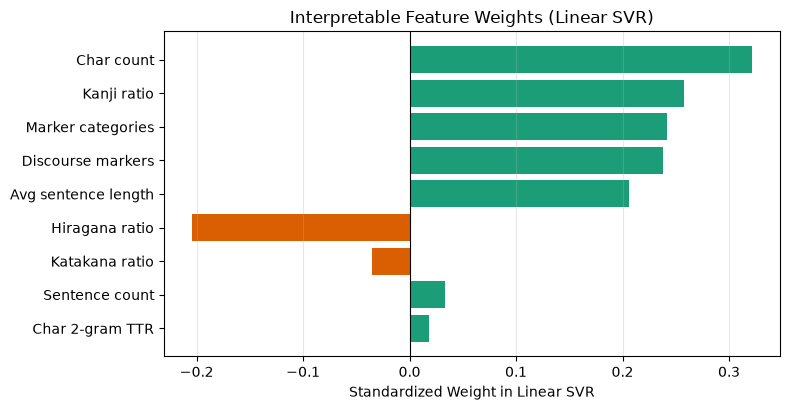


[テストID=8] 正解=5, 切片=2.999, SVR予測=5.007


,素性,標準化値 z,SVR重み w,スコア寄与 (w*z)
0,総文字数,1.79,0.322,0.575
7,接続表現数,1.62,0.238,0.386
2,平均文長,1.65,0.206,0.340
8,接続表現カテゴリ数,1.26,0.242,0.304
3,漢字率,0.89,0.258,0.228



[テストID=9] 正解=2, 切片=2.999, SVR予測=2.176


,素性,標準化値 z,SVR重み w,スコア寄与 (w*z)
8,接続表現カテゴリ数,-1.14,0.242,-0.275
7,接続表現数,-1.08,0.238,-0.257
4,ひらがな率,0.56,-0.204,-0.115
3,漢字率,-0.29,0.258,-0.074
0,総文字数,-0.22,0.322,-0.072


In [2]:
X_es = df_essays[feat_cols].to_numpy()
y_es = df_essays["スコア"].to_numpy()
X_tr_e, X_te_e, y_tr_e, y_te_e, txt_tr_e, txt_te_e = train_test_split(
    X_es, y_es, df_essays["本文"].tolist(), test_size=10, stratify=y_es, random_state=42
)

scaler_e = StandardScaler()
X_tr_ez = scaler_e.fit_transform(X_tr_e)
X_te_ez = scaler_e.transform(X_te_e)

# 1. 分類モデル (LogisticRegression) と予測確率「信頼度」
clf_lr = LogisticRegression(C=1.0, max_iter=1000, random_state=42).fit(X_tr_ez, y_tr_e)
pred_lr = clf_lr.predict(X_te_ez)
probs_lr = clf_lr.predict_proba(X_te_ez)

conf_rows = []
for i, (g, p, pr, txt) in enumerate(zip(y_te_e, pred_lr, probs_lr, txt_te_e)):
    conf_rows.append({
        "テストID": i,
        "正解": int(g),
        "予測": int(p),
        "信頼度(最大確率)": round(float(pr.max()), 3),
        "各スコア確率 [1..5]": [round(float(v), 2) for v in pr],
        "冒頭": txt[:24] + "…",
    })
print(f"LogisticRegression テスト QWK: {cohen_kappa_score(y_te_e, pred_lr, weights='quadratic'):.3f}")
display(pd.DataFrame(conf_rows))

# 2. 線形回帰モデル (SVR linear & Ridge) と素性重み分析
svr_lin = SVR(kernel="linear", C=1.0).fit(X_tr_ez, y_tr_e)
ridge_lin = Ridge(alpha=1.0).fit(X_tr_ez, y_tr_e)

reg_rows = []
for nm, mdl in [("Linear SVR", svr_lin), ("Ridge", ridge_lin)]:
    raw_p = mdl.predict(X_te_ez)
    disc_p = np.clip(np.rint(raw_p), 1, 5).astype(int)
    reg_rows.append({
        "モデル": nm,
        "テスト QWK": round(cohen_kappa_score(y_te_e, disc_p, weights="quadratic"), 3),
        "テスト Spearman ρ": round(float(spearmanr(y_te_e, raw_p).statistic), 3),
        "テスト MAE": round(float(np.mean(np.abs(y_te_e - raw_p))), 3),
    })
print("\n=== 線形回帰モデルのテスト性能 ===")
display(pd.DataFrame(reg_rows))

feat_en = {
    "総文字数": "Char count",
    "文数": "Sentence count",
    "平均文長": "Avg sentence length",
    "漢字率": "Kanji ratio",
    "ひらがな率": "Hiragana ratio",
    "カタカナ率": "Katakana ratio",
    "文字2gram多様性(TTR)": "Char 2-gram TTR",
    "接続表現数": "Discourse markers",
    "接続表現カテゴリ数": "Marker categories",
}

w_svr = svr_lin.coef_.ravel()
w_ridge = ridge_lin.coef_.ravel()
weight_df = pd.DataFrame({
    "素性名": feat_cols,
    "SVR重み": np.round(w_svr, 3),
    "Ridge重み": np.round(w_ridge, 3),
    "|SVR重み|": np.round(np.abs(w_svr), 3),
}).sort_values("|SVR重み|", ascending=False)
print("\n=== 標準化素性の学習済み重み（|SVR重み|降順） ===")
display(weight_df)

fig, ax = plt.subplots(figsize=(8, 4.2))
order_idx = np.argsort(np.abs(w_svr))
ax.barh([feat_en[feat_cols[i]] for i in order_idx], w_svr[order_idx], color=["#d95f02" if v < 0 else "#1b9e77" for v in w_svr[order_idx]])
ax.axvline(0.0, color="black", linewidth=0.8)
ax.set_xlabel("Standardized Weight in Linear SVR")
ax.set_title("Interpretable Feature Weights (Linear SVR)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 3. 個別テスト作文の予測根拠寄与 (w_j * z_j)
for test_i in [8, 9]:  # 高スコア作文と低スコア作文
    contrib = w_svr * X_te_ez[test_i]
    pred_raw = float(svr_lin.intercept_[0] + contrib.sum())
    c_df = pd.DataFrame({
        "素性": feat_cols,
        "標準化値 z": np.round(X_te_ez[test_i], 2),
        "SVR重み w": np.round(w_svr, 3),
        "スコア寄与 (w*z)": np.round(contrib, 3),
    }).sort_values("スコア寄与 (w*z)", key=np.abs, ascending=False)
    print(f"\n[テストID={test_i}] 正解={y_te_e[test_i]}, 切片={svr_lin.intercept_[0]:.3f}, SVR予測={pred_raw:.3f}")
    display(c_df.head(5))

### 第 2 節の観察

- **信頼度の活用**: `LogisticRegression` の予測確率を見ると、テスト ID `8`（正解 5・予測 5）は最大確率 **`0.881`** と高い信頼度を示しているのに対し、テスト ID `1`（正解 4・予測 4）は **`[0.00, 0.01, 0.36, 0.42, 0.21]`**（信頼度 `0.417`）とスコア 3・4 の境界で迷っており、誤分類したテスト ID `9`（正解 2・予測 1）も **`[0.41, 0.37, 0.18, 0.03, 0.01]`**（信頼度 `0.407`）と僅差です。信頼度が低い作文だけを人手確認へ回す運用 (p.68) が有効であることがわかります。
- **線形 SVR / Ridge の解釈可能性**: `総文字数` (`+0.322`)・`漢字率` (`+0.258`)・`接続表現カテゴリ数` (`+0.242`)・`接続表現数` (`+0.238`)・`平均文長` (`+0.206`) に正の重み、`ひらがな率` (`-0.204`) に負の重みが学習され、テスト QWK `1.000`・Spearman $\rho$ `0.985` を達成しています。さらに個別作文ごとに $w_j z_j$ を分解すれば、「なぜこの作文が高評価（あるいは低評価）と予測されたか」を具体的な根拠として説明できます (Hirao et al., 2020)。

---

## 3. 特徴量ベース vs ファインチューニングベースと少データ時の過学習・破壊的忘却（2-3-2・図 2.5）

書籍 2-3-2（図 2.5、p.69〜71）では、事前学習済みモデルを品質推定タスクへ適用する次の 2 つのシステム構成が対比されています。

1. **特徴量ベース（左）**: 事前学習済み表現器の重みを凍結し、文ベクトル $\mathbf{h}(x)$（必要に応じて第 1 節の解釈可能素性を併用）を抽出して、後段の線形 `SVR` 等で学習する。
2. **ファインチューニングベース（右）**: 事前学習済み表現器の重みごと品質スコア予測へエンドツーエンドで更新する。少数の訓練データ（例：$N=12$ 件）に対して大きな表現層を高学習率・多エポックで更新すると、訓練誤差は 0 になっても未知データで精度が落ち、事前学習で獲得していた一般文の意味知識まで壊してしまう**破壊的忘却**（catastrophic forgetting, p.70 脚注 60）が起こりやすくなります。

ここでは外部ネットワークダウンロードに依存せず仕組みを明確に確かめるため、4 トピック（科学技術・環境エネルギー・教育学習・交通都市）の一般コーパス 96 文で事前学習した純 NumPy 製 2 層ニューラル表現器を構築し、一般文ペア 12 組の意味類似度保持率 (Spearman $\rho$) を測りながら次の 3 条件を比較します。
- **(a) 特徴量ベース**: 事前学習済み表現層を凍結し、抽出ベクトル $[\mathbf{h}, \text{作文素性}]$ を線形 `SVR` で学習
- **(b) 控えめなファインチューニング**: 小さな表現層学習率・L2 正則化・早期停止 (`epochs=35`)
- **(c) 過剰なファインチューニング**: 高学習率・正則化なし・多エポック (`epochs=200`) で表現層全体を更新

事前学習直後の一般文意味類似度 Spearman 相関: 0.869


,訓練件数,手法,訓練MSE,未知QWK,未知Spearman,事前知識保持率
0,N=12,(a) 特徴量ベース（表現凍結 + 線形SVR）,0.007,0.828,0.960,0.869
1,N=12,(b) 控えめな微調整（微小学習率・早期停止）,0.011,0.815,0.911,0.869
2,N=12,(c) 過剰な微調整（高学習率・多エポック）,0.000,0.750,0.935,0.097
3,N=20,(a) 特徴量ベース（表現凍結 + 線形SVR）,0.008,0.941,0.985,0.869
4,N=20,(b) 控えめな微調整（微小学習率・早期停止）,0.006,0.774,0.862,0.869
5,N=20,(c) 過剰な微調整（高学習率・多エポック）,0.205,0.690,0.867,0.531


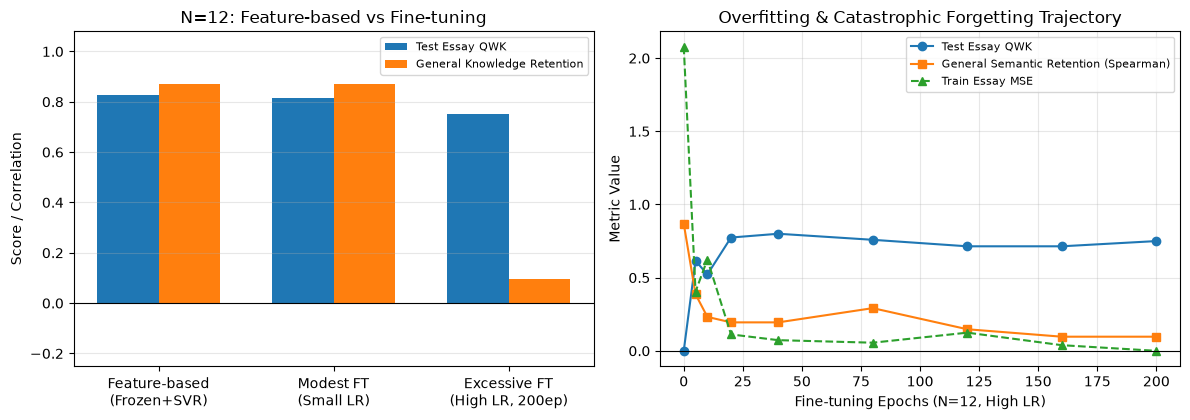

In [3]:
# 1. 一般コーパス 96 文で軽量 MLP 表現器を事前学習（純 NumPy）
gen_templates = {
    0: [
        "機械学習モデルが大量のデータから特徴を自動で学習する。",
        "自然言語処理の技術により高精度な翻訳が可能になった。",
        "ニューラルネットワークの多層化が画像認識を飛躍させた。",
        "計算資源の効率化によって推論速度が大幅に向上した。",
        "深層学習のアルゴリズムは音声認識にも応用されている。",
        "統計的手法とデータ分析が科学技術の発展を支える。",
    ],
    1: [
        "太陽光や風力などの再生可能エネルギーの導入が進んでいる。",
        "森林保全と二酸化炭素の削減が地球温暖化対策の柱だ。",
        "自治体によるリサイクル推進で廃棄物の量が減った。",
        "海洋プラスチック問題の解決に向けた国際協力が始まった。",
        "省エネ家電の普及が家庭の電力消費を抑えている。",
        "蓄電池技術が自然エネルギーの安定供給を助ける。",
    ],
    2: [
        "学校現場でデジタル教材を使った対話的な授業が広がる。",
        "図書館の活用は子どもたちの読解力と語彙力を育てる。",
        "毎日の読書習慣が論理的な文章を書く基礎を作る。",
        "グループ学習を通じて生徒同士が議論を深めている。",
        "英語のリスニング練習を毎日少しずつ続けることが大切だ。",
        "探究学習では課題設定から調査発表まで自ら行う。",
    ],
    3: [
        "鉄道会社は深夜の保守作業時間を確保するためダイヤを見直した。",
        "自動運転バスの実証実験が地方都市の幹線道路で行われた。",
        "駅前商店街の活性化に向けて歩行者空間の整備が進む。",
        "自転車専用レーンの設置により通勤時の安全性が高まった。",
        "公共交通の利便性向上は高齢者の外出機会を増やす。",
        "都市の公園整備は災害時の避難場所としても機能する。",
    ],
}

gen_sents, gen_labels = [], []
rng_g = np.random.default_rng(7)
for lbl, sents in gen_templates.items():
    for s in sents:
        gen_sents.append(s)
        gen_labels.append(lbl)
    for _ in range(18):
        s1, s2 = rng_g.choice(sents, size=2, replace=False)
        gen_sents.append(s1[:-1] + "。また、" + s2)
        gen_labels.append(lbl)

# 事前知識保持率の評価用ベンチマーク: 一般文ペア 12 組（同トピック 6 組=1.0, 異トピック 6 組=0.0）
sem_pairs = [
    ("深層学習アルゴリズムは画像や音声認識に応用される。", "ニューラルネットワークが画像認識の精度を飛躍させた。", 1.0),
    ("太陽光や風力などの自然エネルギー導入が進む。", "再生可能エネルギーの安定供給に蓄電池技術が役立つ。", 1.0),
    ("デジタル教材を用いた対話的な授業が学校で広がる。", "探究学習では生徒が自ら課題を設定し議論を深める。", 1.0),
    ("自動運転バスの実証実験が都市の幹線道路で始まった。", "公共交通の利便性を高めるため駅周辺の整備が進む。", 1.0),
    ("自然言語処理モデルが大量データから特徴を学習する。", "統計的手法とデータ分析により機械学習の精度が上がる。", 1.0),
    ("森林保全と省エネ家電が温暖化対策に貢献する。", "リサイクル推進と二酸化炭素削減で環境を守る。", 1.0),
    ("深層学習アルゴリズムは画像や音声認識に応用される。", "駅前商店街の活性化と歩行者空間の整備が進む。", 0.0),
    ("太陽光や風力などの自然エネルギー導入が進む。", "英語のリスニング練習を毎日少しずつ続ける。", 0.0),
    ("デジタル教材を用いた対話的な授業が学校で広がる。", "鉄道会社が保守作業時間確保のためダイヤを見直した。", 0.0),
    ("自動運転バスの実証実験が都市の幹線道路で始まった。", "海洋プラスチック問題の解決へ国際協力が始まった。", 0.0),
    ("図書館の活用は子どもたちの読解力を育てる。", "計算資源の効率化によって推論速度が向上した。", 0.0),
    ("森林保全と省エネ家電が温暖化対策に貢献する。", "グループ学習を通じて生徒同士が議論を深めている。", 0.0),
]

vec_enc = TfidfVectorizer(analyzer="char", ngram_range=(2, 3), max_features=1200, sublinear_tf=True, norm="l2")
vec_enc.fit(gen_sents + df_essays["本文"].tolist())
stat_sc = StandardScaler().fit(
    np.array([[v for v in extract_essay_features(t).values()] for t in gen_sents + df_essays["本文"].tolist()])
)

def enc_text(texts):
    return vec_enc.transform(texts).toarray() * 4.0

def enc_stat(texts):
    return stat_sc.transform(np.array([[v for v in extract_essay_features(t).values()] for t in texts]))

def relu(z):
    return np.maximum(0.0, z)

def d_relu(z):
    return (z > 0).astype(float)

def pretrain_encoder(X, y_top, y_st, h1=64, h2=24, epochs=240, lr=0.06, seed=42):
    rng = np.random.default_rng(seed)
    d = X.shape[1]
    W1 = rng.normal(0, np.sqrt(2.0 / d), (d, h1))
    b1 = np.zeros(h1)
    W2 = rng.normal(0, np.sqrt(2.0 / h1), (h1, h2))
    b2 = np.zeros(h2)
    Wc = rng.normal(0, np.sqrt(2.0 / h2), (h2, 4))
    bc = np.zeros(4)
    Ws = rng.normal(0, np.sqrt(2.0 / h2), (h2, y_st.shape[1]))
    bs = np.zeros(y_st.shape[1])
    Y = np.eye(4)[y_top]
    n = len(X)
    for _ in range(epochs):
        z1 = X @ W1 + b1
        a1 = relu(z1)
        z2 = a1 @ W2 + b2
        a2 = relu(z2)
        lg = a2 @ Wc + bc
        lg -= lg.max(axis=1, keepdims=True)
        pr = np.exp(lg) / np.exp(lg).sum(axis=1, keepdims=True)
        dl = (pr - Y) / n
        ds = 0.25 * (a2 @ Ws + bs - y_st) / n
        dz2 = (dl @ Wc.T + ds @ Ws.T) * d_relu(z2)
        dz1 = (dz2 @ W2.T) * d_relu(z1)
        Wc -= lr * (a2.T @ dl + 1e-4 * Wc)
        bc -= lr * dl.sum(axis=0)
        Ws -= lr * (a2.T @ ds + 1e-4 * Ws)
        bs -= lr * ds.sum(axis=0)
        W2 -= lr * (a1.T @ dz2 + 1e-4 * W2)
        b2 -= lr * dz2.sum(axis=0)
        W1 -= lr * (X.T @ dz1 + 1e-4 * W1)
        b1 -= lr * dz1.sum(axis=0)
    return (W1, b1, W2, b2)

def fwd_enc(X, params):
    W1, b1, W2, b2 = params
    return relu(relu(X @ W1 + b1) @ W2 + b2)

def eval_general_retention(params):
    ha = fwd_enc(enc_text([x[0] for x in sem_pairs]), params)
    hb = fwd_enc(enc_text([x[1] for x in sem_pairs]), params)
    cos = np.sum(ha * hb, axis=1) / (np.linalg.norm(ha, axis=1) * np.linalg.norm(hb, axis=1) + 1e-12)
    return float(spearmanr([x[2] for x in sem_pairs], cos).statistic)

X_gen = enc_text(gen_sents)
gen_struct = enc_stat(gen_sents)[:, [0, 3, 7, 8]]
pre_params = pretrain_encoder(X_gen, np.array(gen_labels), gen_struct)
base_ret = eval_general_retention(pre_params)
print(f"事前学習直後の一般文意味類似度 Spearman 相関: {base_ret:.3f}")

# 2. 作文データでの特徴量ベース vs ファインチューニング比較 (N=12 / N=20)
X_ess_txt = enc_text(df_essays["本文"].tolist())
X_ess_st = enc_stat(df_essays["本文"].tolist())
idx_all = np.arange(len(df_essays))
idx_tr20, idx_te10 = train_test_split(idx_all, test_size=10, stratify=y_es, random_state=42)
idx_tr12, _ = train_test_split(idx_tr20, train_size=12, stratify=y_es[idx_tr20], random_state=42)

def run_finetune(Xtr, ytr, Xte, yte, pre, lr_enc, lr_head, epochs, reg=0.0, bs=4, seed=42, eval_every=None):
    rng = np.random.default_rng(seed)
    pl = [p.copy() for p in pre] + [rng.normal(0, 0.05, pre[2].shape[1]), np.array([float(np.mean(ytr))])]
    lrs = [lr_enc, lr_enc, lr_enc, lr_enc, lr_head, lr_head]
    m = [np.zeros_like(x) for x in pl]
    v = [np.zeros_like(x) for x in pl]
    step, n = 0, len(Xtr)
    hist = []
    def snapshot(ep):
        enc = tuple(pl[:4])
        ptr = fwd_enc(Xtr, enc) @ pl[4] + pl[5][0]
        pte = fwd_enc(Xte, enc) @ pl[4] + pl[5][0]
        return {
            "epoch": ep,
            "tr_mse": float(mean_squared_error(ytr, ptr)),
            "te_qwk": float(cohen_kappa_score(yte, np.clip(np.rint(pte), 1, 5).astype(int), weights="quadratic")),
            "te_rho": float(spearmanr(yte, pte).statistic),
            "gen_ret": eval_general_retention(enc),
        }
    if eval_every:
        hist.append(snapshot(0))
    for ep in range(1, epochs + 1):
        perm = rng.permutation(n)
        for st in range(0, n, bs):
            ib = perm[st:st + bs]
            Xb, yb = Xtr[ib], ytr[ib]
            z1 = Xb @ pl[0] + pl[1]
            a1 = relu(z1)
            z2 = a1 @ pl[2] + pl[3]
            a2 = relu(z2)
            pr = a2 @ pl[4] + pl[5][0]
            err = 2.0 * (pr - yb) / len(Xb)
            dz2 = np.outer(err, pl[4]) * d_relu(z2)
            dz1 = (dz2 @ pl[2].T) * d_relu(z1)
            gs = [
                Xb.T @ dz1 + reg * pl[0],
                dz1.sum(axis=0),
                a1.T @ dz2 + reg * pl[2],
                dz2.sum(axis=0),
                a2.T @ err + reg * pl[4],
                np.array([err.sum()]),
            ]
            step += 1
            for k in range(len(pl)):
                g = np.clip(gs[k], -5.0, 5.0)
                m[k] = 0.9 * m[k] + 0.1 * g
                v[k] = 0.999 * v[k] + 0.001 * (g ** 2)
                pl[k] -= lrs[k] * (m[k] / (1 - 0.9 ** step)) / (np.sqrt(v[k] / (1 - 0.999 ** step)) + 1e-8)
        if eval_every and ep in eval_every:
            hist.append(snapshot(ep))
    final = snapshot(epochs)
    return final, hist

comp_rows = []
for n_lbl, tr_idx in [("N=12", idx_tr12), ("N=20", idx_tr20)]:
    Xtr, ytr = X_ess_txt[tr_idx], y_es[tr_idx]
    Xte, yte = X_ess_txt[idx_te10], y_es[idx_te10]
    ftr = np.hstack([fwd_enc(Xtr, pre_params), X_ess_st[tr_idx]])
    fte = np.hstack([fwd_enc(Xte, pre_params), X_ess_st[idx_te10]])
    sc_f = StandardScaler()
    svr_fb = SVR(kernel="linear", C=0.5).fit(sc_f.fit_transform(ftr), ytr)
    ptr_fb, pte_fb = svr_fb.predict(sc_f.transform(ftr)), svr_fb.predict(sc_f.transform(fte))
    comp_rows.append({
        "訓練件数": n_lbl,
        "手法": "(a) 特徴量ベース（表現凍結 + 線形SVR）",
        "訓練MSE": round(mean_squared_error(ytr, ptr_fb), 3),
        "未知QWK": round(cohen_kappa_score(yte, np.clip(np.rint(pte_fb), 1, 5).astype(int), weights="quadratic"), 3),
        "未知Spearman": round(float(spearmanr(yte, pte_fb).statistic), 3),
        "事前知識保持率": round(base_ret, 3),
    })

    for m_lbl, le, lh, ep, reg in [
        ("(b) 控えめな微調整（微小学習率・早期停止）", 3e-4, 8e-3, 35, 0.05),
        ("(c) 過剰な微調整（高学習率・多エポック）", 5e-2, 5e-2, 200, 0.0),
    ]:
        res, _ = run_finetune(Xtr, ytr, Xte, yte, pre_params, le, lh, ep, reg=reg)
        comp_rows.append({
            "訓練件数": n_lbl,
            "手法": m_lbl,
            "訓練MSE": round(res["tr_mse"], 3),
            "未知QWK": round(res["te_qwk"], 3),
            "未知Spearman": round(res["te_rho"], 3),
            "事前知識保持率": round(res["gen_ret"], 3),
        })

comp_df = pd.DataFrame(comp_rows)
display(comp_df)

# 3. N=12 で過剰なファインチューニングを進めたときのエポック推移と破壊的忘却の可視化
_, traj = run_finetune(
    X_ess_txt[idx_tr12], y_es[idx_tr12], X_ess_txt[idx_te10], y_es[idx_te10],
    pre_params, lr_enc=5e-2, lr_head=5e-2, epochs=200, reg=0.0,
    eval_every={5, 10, 20, 40, 80, 120, 160, 200},
)
traj_df = pd.DataFrame(traj)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# Left: Method comparison at N=12
sub12 = comp_df[comp_df["訓練件数"] == "N=12"]
x = np.arange(3)
w = 0.35
short_labels = ["Feature-based\n(Frozen+SVR)", "Modest FT\n(Small LR)", "Excessive FT\n(High LR, 200ep)"]
axes[0].bar(x - w / 2, sub12["未知QWK"].to_numpy(), width=w, label="Test Essay QWK")
axes[0].bar(x + w / 2, sub12["事前知識保持率"].to_numpy(), width=w, label="General Knowledge Retention")
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_labels)
axes[0].set_ylim(-0.25, 1.08)
axes[0].axhline(0.0, color="black", linewidth=0.8)
axes[0].set_ylabel("Score / Correlation")
axes[0].set_title("N=12: Feature-based vs Fine-tuning")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

# Right: Epoch trajectory under excessive fine-tuning (N=12)
axes[1].plot(traj_df["epoch"], traj_df["te_qwk"], marker="o", label="Test Essay QWK")
axes[1].plot(traj_df["epoch"], traj_df["gen_ret"], marker="s", label="General Semantic Retention (Spearman)")
axes[1].plot(traj_df["epoch"], traj_df["tr_mse"], marker="^", linestyle="--", label="Train Essay MSE")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_xlabel("Fine-tuning Epochs (N=12, High LR)")
axes[1].set_ylabel("Metric Value")
axes[1].set_title("Overfitting & Catastrophic Forgetting Trajectory")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 第 3 節の観察と実務向けの事前学習モデル活用例

1. **特徴量ベース vs ファインチューニングベース**:
   - **(a) 特徴量ベース（表現層凍結 + 線形 `SVR`）**: $N=12$ で未知 QWK **`0.828`**（未知 Spearman `0.960`）、$N=20$ では未知 QWK **`0.941`**（未知 Spearman `0.985`）と高い汎化性能を保ちつつ、事前学習済み表現器の重みを一切更新しないため一般文意味類似度の保持率 **`0.869`** が **100% 維持** されます。
   - **(b) 控えめなファインチューニング**: 小さな学習率と L2 正則化・早期停止を組み合わせることで、$N=12$ でも未知 QWK `0.815`・事前知識保持率 `0.869` を維持できます。
   - **(c) 過剰なファインチューニング**: $N=12$ の少量データに対し高学習率で全層を更新すると、訓練 MSE は **`0.000`** まで下がりきりますが、未知データの QWK は **`0.750`**（$N=20$ でも **`0.690`**）へ低下し、一般文ペアの意味類似度順位に至っては **`0.869` → `0.097`** へと大きく崩れる**破壊的忘却**が確認できます。

### 参考：日本語 BERT (`tohoku-nlp/bert-base-japanese-v3`) を特徴抽出器として凍結し `SVR` へ渡す実装例

実務で事前学習済みトランスフォーマーを「特徴量ベース」（図 2.5 左）として使う場合は、以下のように勾配更新なしで `<CLS>` (`last_hidden_state[:, 0]`) や平均プーリングを取り出し、`StandardScaler` と線形 `SVR` へ渡します（本セルは GPU 環境や `transformers` 利用時の参考コードであり、このノートブック内では実行しません）。

```python
import numpy as np
import torch
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from transformers import AutoModel, AutoTokenizer

model_name = "tohoku-nlp/bert-base-japanese-v3"
tok = AutoTokenizer.from_pretrained(model_name)
bert = AutoModel.from_pretrained(model_name).eval()

@torch.no_grad()
def extract_cls_features(texts):
    enc = tok(texts, padding=True, truncation=True, max_length=256, return_tensors="pt")
    out = bert(**enc)
    return out.last_hidden_state[:, 0, :].cpu().numpy()

# X_cls_tr = extract_cls_features(train_texts)
# reg = make_pipeline(StandardScaler(), SVR(kernel="linear", C=1.0)).fit(X_cls_tr, y_train)
```